# WOE / IV Encoding
**Input:** `cs_training_cleaned.csv` (output từ Bước 1)  
**Output:** `cs_woe_transformed.csv` + `woe_bins.pkl` (dùng cho Bước 3)

**Notebook Structure**
1. Load dữ liệu & setup
2. Binning tự động với `scorecardpy`
3. Điều chỉnh binning thủ công (fine-tuning)
4. Phân tích IV — chọn & loại biến
5. Visualize WOE bins từng feature
6. Transform dữ liệu sang WOE values
7. Kiểm tra monotonicity & sanity check
8. Lưu bins + dữ liệu đã transform

### Load dữ liệu & Setup

In [12]:
!pip install scorecardpy
import warnings, pickle
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scorecardpy as sc

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", 20)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
})

PALETTE = {"good": "#2196F3", "bad": "#E53935", "neutral": "#78909C",
           "woe_pos": "#1976D2", "woe_neg": "#C62828", "iv_bar": "#5C6BC0"}

# ── Load clean data từ Bước 1 ───────────────────────────────────────────────
df = pd.read_csv("../EDA Cleaning/cs_training_cleaned.csv")

# scorecardpy yêu cầu tên cột target là bất kỳ nhưng phải int 0/1
assert df["target"].isin([0, 1]).all(), "target phải là 0/1"

print(f"✓ Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"  Bad rate: {df['target'].mean()*100:.2f}%")
print(f"  Columns : {list(df.columns)}")

✓ Loaded: 150,000 rows × 12 columns
  Bad rate: 6.68%
  Columns : ['target', 'revolving_util', 'age', 'past_due_30_59', 'debt_ratio', 'monthly_income', 'open_credit_lines', 'late_90_days', 'real_estate_loans', 'past_due_60_89', 'dependents', 'monthly_income_missing']


### 2. Binning tự động với `scorecardpy`

`sc.woebin()` dùng thuật toán **Monotone Optimal Binning** — tự động tìm số bins tối ưu  
sao cho WOE có xu hướng đơn điệu (monotone) theo thứ tự bins.

In [90]:
# ── Danh sách feature columns (loại trừ target và flag) ─────────────────────
FEATURE_COLS = [
    "revolving_util", "age", "past_due_30_59", "debt_ratio",
    "monthly_income", "open_credit_lines", "late_90_days",
    "real_estate_loans", "past_due_60_89", "dependents",
]

# ── Auto binning ─────────────────────────────────────────────────────────────
# breaks_adj: cho phép điều chỉnh thủ công nếu cần (để {} để tự động hoàn toàn)
print("Đang chạy auto binning... (mất khoảng 10-30 giây)")

bins_auto = sc.woebin(
    df[FEATURE_COLS + ["target"]],
    y="target",
    bin_num_limit=10,        # tối đa 10 bins mỗi biến
    positive="bad|1",        # định nghĩa nhãn "bad"
    print_step=0,            # tắt verbose output
)

print("✓ Auto binning hoàn tất")
print(f"  Số biến được bin: {len(bins_auto)}")


Đang chạy auto binning... (mất khoảng 10-30 giây)
[INFO] creating woe binning ...


/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:320: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  init_bin = dtm.groupby('bin', group_keys=False)['y'].agg([n0, n1])\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:320: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  init_bin = dtm.groupby('bin', group_keys=False)['y'].agg([n0, n1])\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. 

✓ Auto binning hoàn tất
  Số biến được bin: 10


/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:425: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to 

In [91]:
# ── Xem kết quả binning thô cho 1 biến mẫu ──────────────────────────────────
sample_var = "past_due_30_59"
print(f"Binning kết quả cho: {sample_var}")
print(bins_auto[sample_var][
    ["bin", "count", "count_distr", "good", "bad", "badprob", "woe", "bin_iv"]
].to_string(index=False))


Binning kết quả cho: past_due_30_59
       bin  count  count_distr   good  bad  badprob     woe  bin_iv
[-inf,1.0) 126018       0.8401 120977 5041   0.0400 -0.5417  0.1958
 [1.0,2.0)  16033       0.1069  13624 2409   0.1503  0.9037  0.1292
 [2.0,inf)   7949       0.0530   5373 2576   0.3241  1.9011  0.4155


#### Binning kết quả cho: `past_due_30_59`

Bảng trên thể hiện kết quả **phân bin** cho biến `past_due_30_59` — số lần khách hàng từng quá hạn thanh toán **30–59 ngày**.

#### Phân tích từng bin

- **`[-inf, 1.0)`** — Chiếm 84% dữ liệu, xác suất vỡ nợ chỉ **4%**, WOE = -0.54 → nhóm **rủi ro thấp**
- **`[1.0, 2.0)`** — Chiếm 10.7%, xác suất vỡ nợ **15%**, WOE = 0.90 → rủi ro **trung bình**
- **`[2.0, inf)`** — Chiếm 5.3%, xác suất vỡ nợ **32.4%**, WOE = 1.90 → nhóm **rủi ro cao nhất**

### Nhận xét

WOE tăng đều từ âm → dương theo số lần quá hạn, cho thấy biến có **tính đơn điệu tốt**.  
Tổng IV ≈ **0.74** → predictive power **rất mạnh**, nên ưu tiên giữ lại trong model.

### 3. Điều chỉnh Binning thủ công (Fine-tuning)

Auto binning đôi khi tạo ra bins quá nhiều hoặc phá vỡ monotonicity.  
Ta điều chỉnh bằng tham số `breaks_adj` — chỉ định điểm cắt thủ công cho những biến cần chỉnh.

**Nguyên tắc điều chỉnh:**
- Mỗi bin nên có ít nhất **5% tổng số records**
- WOE nên **đơn điệu** (tăng dần hoặc giảm dần) theo thứ tự bins
- Số bins lý tưởng: **4–6 bins** cho biến liên tục

In [158]:
BREAKS_ADJ = {
    "past_due_30_59":    [1, 3],
    "past_due_60_89":    [1, 2],
    "late_90_days":      [1, 2],
    "revolving_util":    [0.30, 0.60, 0.90],
    "age":               [35, 50, 65],
    "debt_ratio":        [0.35, 0.50],
    "open_credit_lines": [3, 6],
    "real_estate_loans": [1],
}

print("Đang chạy fine-tuned binning...")
bins_final = sc.woebin(
    df[FEATURE_COLS + ["target"]],
    y="target",
    breaks_list=BREAKS_ADJ,
    bin_num_limit=10,
    positive="bad|1",
    print_step=0,
)
print("✓ Fine-tuned binning hoàn tất")

Đang chạy fine-tuned binning...
[INFO] creating woe binning ...


/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:320: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  init_bin = dtm.groupby('bin', group_keys=False)['y'].agg([n0, n1])\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pas

✓ Fine-tuned binning hoàn tất


/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/lib/python3.12/site-packages/scorecardpy/woebin.py:425: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to 

In [159]:
for var in ["open_credit_lines", "debt_ratio", "real_estate_loans"]:
    print(f"\n{'='*55}")
    print(f"  {var}")
    print('='*55)
    print(bins_final[var][["bin","count","count_distr","good","bad","badprob","woe"]].to_string(index=False))


  open_credit_lines
       bin  count  count_distr  good  bad  badprob     woe
[-inf,3.0)  12992       0.0866 11314 1678   0.1292  0.7278
 [3.0,6.0)  33598       0.2240 31354 2244   0.0668 -0.0008
 [6.0,inf) 103410       0.6894 97306 6104   0.0590 -0.1326

  debt_ratio
        bin  count  count_distr  good  bad  badprob     woe
[-inf,0.35)  72060       0.4804 67869 4191   0.0582 -0.1484
 [0.35,0.5)  21642       0.1443 20178 1464   0.0676  0.0129
  [0.5,inf)  56298       0.3753 51927 4371   0.0776  0.1614

  real_estate_loans
       bin  count  count_distr  good  bad  badprob     woe
[-inf,1.0)  56188       0.3746 51516 4672   0.0831  0.2360
 [1.0,inf)  93812       0.6254 88458 5354   0.0571 -0.1684


In [160]:
# ── So sánh auto vs fine-tuned cho past_due_30_59 ────────────────────────────
print("=== AUTO BINNING ===")
print(bins_auto["past_due_30_59"][["bin","count","badprob","woe","bin_iv"]].to_string(index=False))

print("\n=== FINE-TUNED BINNING ===")
print(bins_final["past_due_30_59"][["bin","count","badprob","woe","bin_iv"]].to_string(index=False))

=== AUTO BINNING ===
       bin  count  badprob     woe  bin_iv
[-inf,1.0) 126018   0.0400 -0.5417  0.1958
 [1.0,2.0)  16033   0.1503  0.9037  0.1292
 [2.0,inf)   7949   0.3241  1.9011  0.4155

=== FINE-TUNED BINNING ===
       bin  count  badprob     woe  bin_iv
[-inf,1.0) 126018   0.0400 -0.5417  0.1958
 [1.0,3.0)  20631   0.1759  1.0916  0.2624
 [3.0,inf)   3351   0.4050  2.2514  0.2727


### 4. Phân tích IV — Chọn & Loại biến

In [162]:
# ── Tổng hợp IV toàn bộ biến ────────────────────────────────────────────────
def compute_iv_summary(bins: dict) -> pd.DataFrame:
    """
    Tổng hợp IV của tất cả biến từ bins dict.
    Thêm cột: số bins, IV classification, và quyết định keep/drop.
    """
    rows = []
    for var, tbl in bins.items():
        iv_total  = tbl["bin_iv"].sum()
        n_bins    = len(tbl)
        max_woe   = tbl["woe"].max()
        min_woe   = tbl["woe"].min()
        woe_range = max_woe - min_woe

        if iv_total < 0.02:
            classification = "Negligible"
            decision = "DROP"
        elif iv_total < 0.1:
            classification = "Weak"
            decision = "CONSIDER"
        elif iv_total < 0.3:
            classification = "Medium"
            decision = "KEEP"
        elif iv_total <= 0.5:
            classification = "Strong"
            decision = "KEEP ★"
        else:
            classification = "Suspicious"
            decision = "INVESTIGATE"

        rows.append({
            "Variable":       var,
            "IV":             round(iv_total, 4),
            "# Bins":         n_bins,
            "WOE Range":      round(woe_range, 3),
            "Classification": classification,
            "Decision":       decision,
        })

    return (pd.DataFrame(rows)
              .sort_values("IV", ascending=False)
              .reset_index(drop=True))

iv_summary = compute_iv_summary(bins_final)
print(iv_summary.to_string(index=False))

         Variable     IV  # Bins  WOE Range Classification    Decision
   revolving_util 1.0589       4     2.5410     Suspicious INVESTIGATE
     late_90_days 0.8733       3     3.2330     Suspicious INVESTIGATE
   past_due_30_59 0.7309       3     2.7930     Suspicious INVESTIGATE
   past_due_60_89 0.5990       3     3.0450     Suspicious INVESTIGATE
              age 0.2326       4     1.5880         Medium        KEEP
open_credit_lines 0.0744       3     0.8600           Weak    CONSIDER
   monthly_income 0.0691       4     0.7520           Weak    CONSIDER
real_estate_loans 0.0396       2     0.4040           Weak    CONSIDER
       dependents 0.0338       4     0.5020           Weak    CONSIDER
       debt_ratio 0.0204       3     0.3100           Weak    CONSIDER


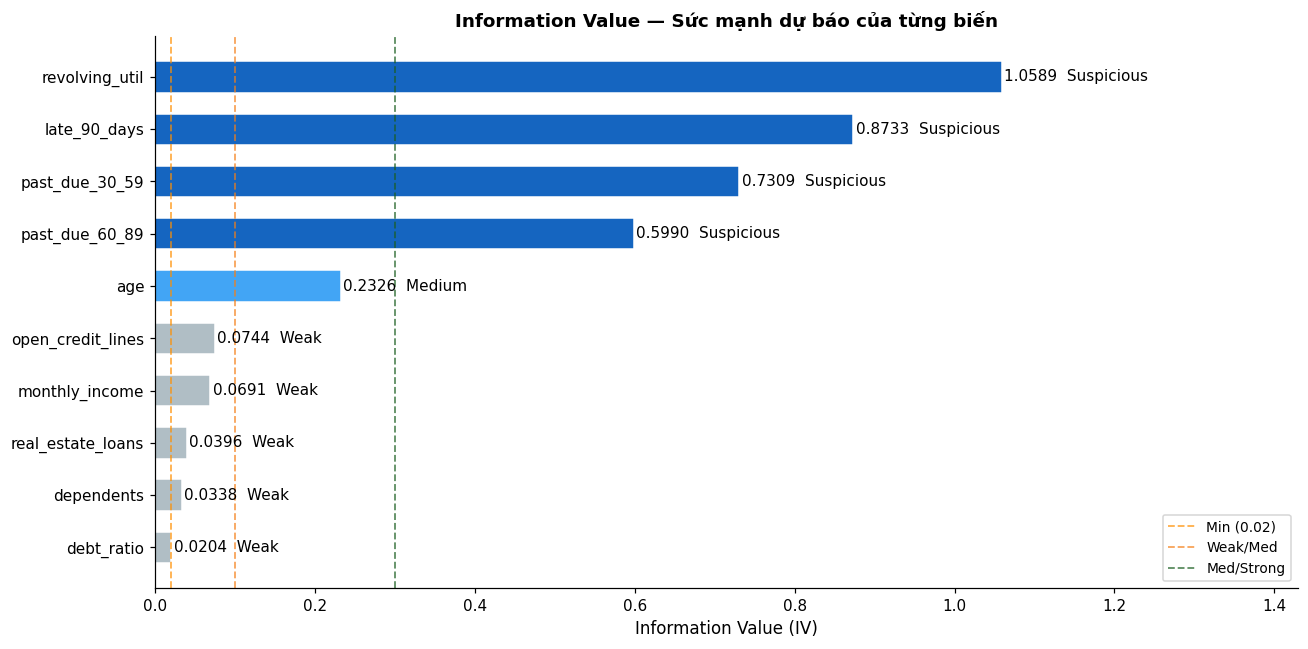

In [163]:
# ── Visualize IV bar chart ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

colors = []
for _, row in iv_summary.iterrows():
    if row["IV"] >= 0.3:
        colors.append("#1565C0")    # mạnh — xanh đậm
    elif row["IV"] >= 0.1:
        colors.append("#42A5F5")    # trung bình — xanh nhạt
    elif row["IV"] >= 0.02:
        colors.append("#B0BEC5")    # yếu — xám
    else:
        colors.append("#EF9A9A")    # loại bỏ — đỏ nhạt

bars = ax.barh(
    iv_summary["Variable"][::-1],
    iv_summary["IV"][::-1],
    color=colors[::-1],
    height=0.6,
    edgecolor="white",
)

# Thêm giá trị IV và nhãn classification
for bar, (_, row) in zip(bars, iv_summary[::-1].iterrows()):
    ax.text(bar.get_width() + 0.003,
            bar.get_y() + bar.get_height() / 2,
            f"{row['IV']:.4f}  {row['Classification']}",
            va="center", fontsize=10)

# Vạch ngưỡng
for thresh, label, color in [
    (0.02, "Min (0.02)", "#FF8F00"),
    (0.1,  "Weak/Med",  "#F57F17"),
    (0.3,  "Med/Strong","#1B5E20"),
]:
    ax.axvline(thresh, color=color, linestyle="--", linewidth=1.2,
               alpha=0.7, label=label)

ax.set_xlabel("Information Value (IV)", fontsize=11)
ax.set_title("Information Value — Sức mạnh dự báo của từng biến", fontsize=12)
ax.legend(fontsize=9, loc="lower right")
ax.set_xlim(0, iv_summary["IV"].max() * 1.35)
plt.tight_layout()
plt.savefig("07_iv_summary.png", bbox_inches="tight")
plt.show()

In [164]:
# ── Xác định biến sẽ giữ lại ────────────────────────────────────────────────
SELECTED_VARS = iv_summary.loc[
    iv_summary["IV"] >= 0.02, "Variable"
].tolist()

DROPPED_VARS = iv_summary.loc[
    iv_summary["IV"] < 0.02, "Variable"
].tolist()

print(f"✓ Giữ lại : {len(SELECTED_VARS)} biến → {SELECTED_VARS}")
print(f"✗ Loại bỏ : {len(DROPPED_VARS)} biến → {DROPPED_VARS}")

✓ Giữ lại : 10 biến → ['revolving_util', 'late_90_days', 'past_due_30_59', 'past_due_60_89', 'age', 'open_credit_lines', 'monthly_income', 'real_estate_loans', 'dependents', 'debt_ratio']
✗ Loại bỏ : 0 biến → []


### 5. Visualize WOE Bins từng Feature

Mỗi chart gồm 2 phần:
- **Bar trái (xanh/đỏ):** WOE value — dương = tốt, âm = rủi ro
- **Line (cam):** Bad rate % — xu hướng monotone là lý tưởng


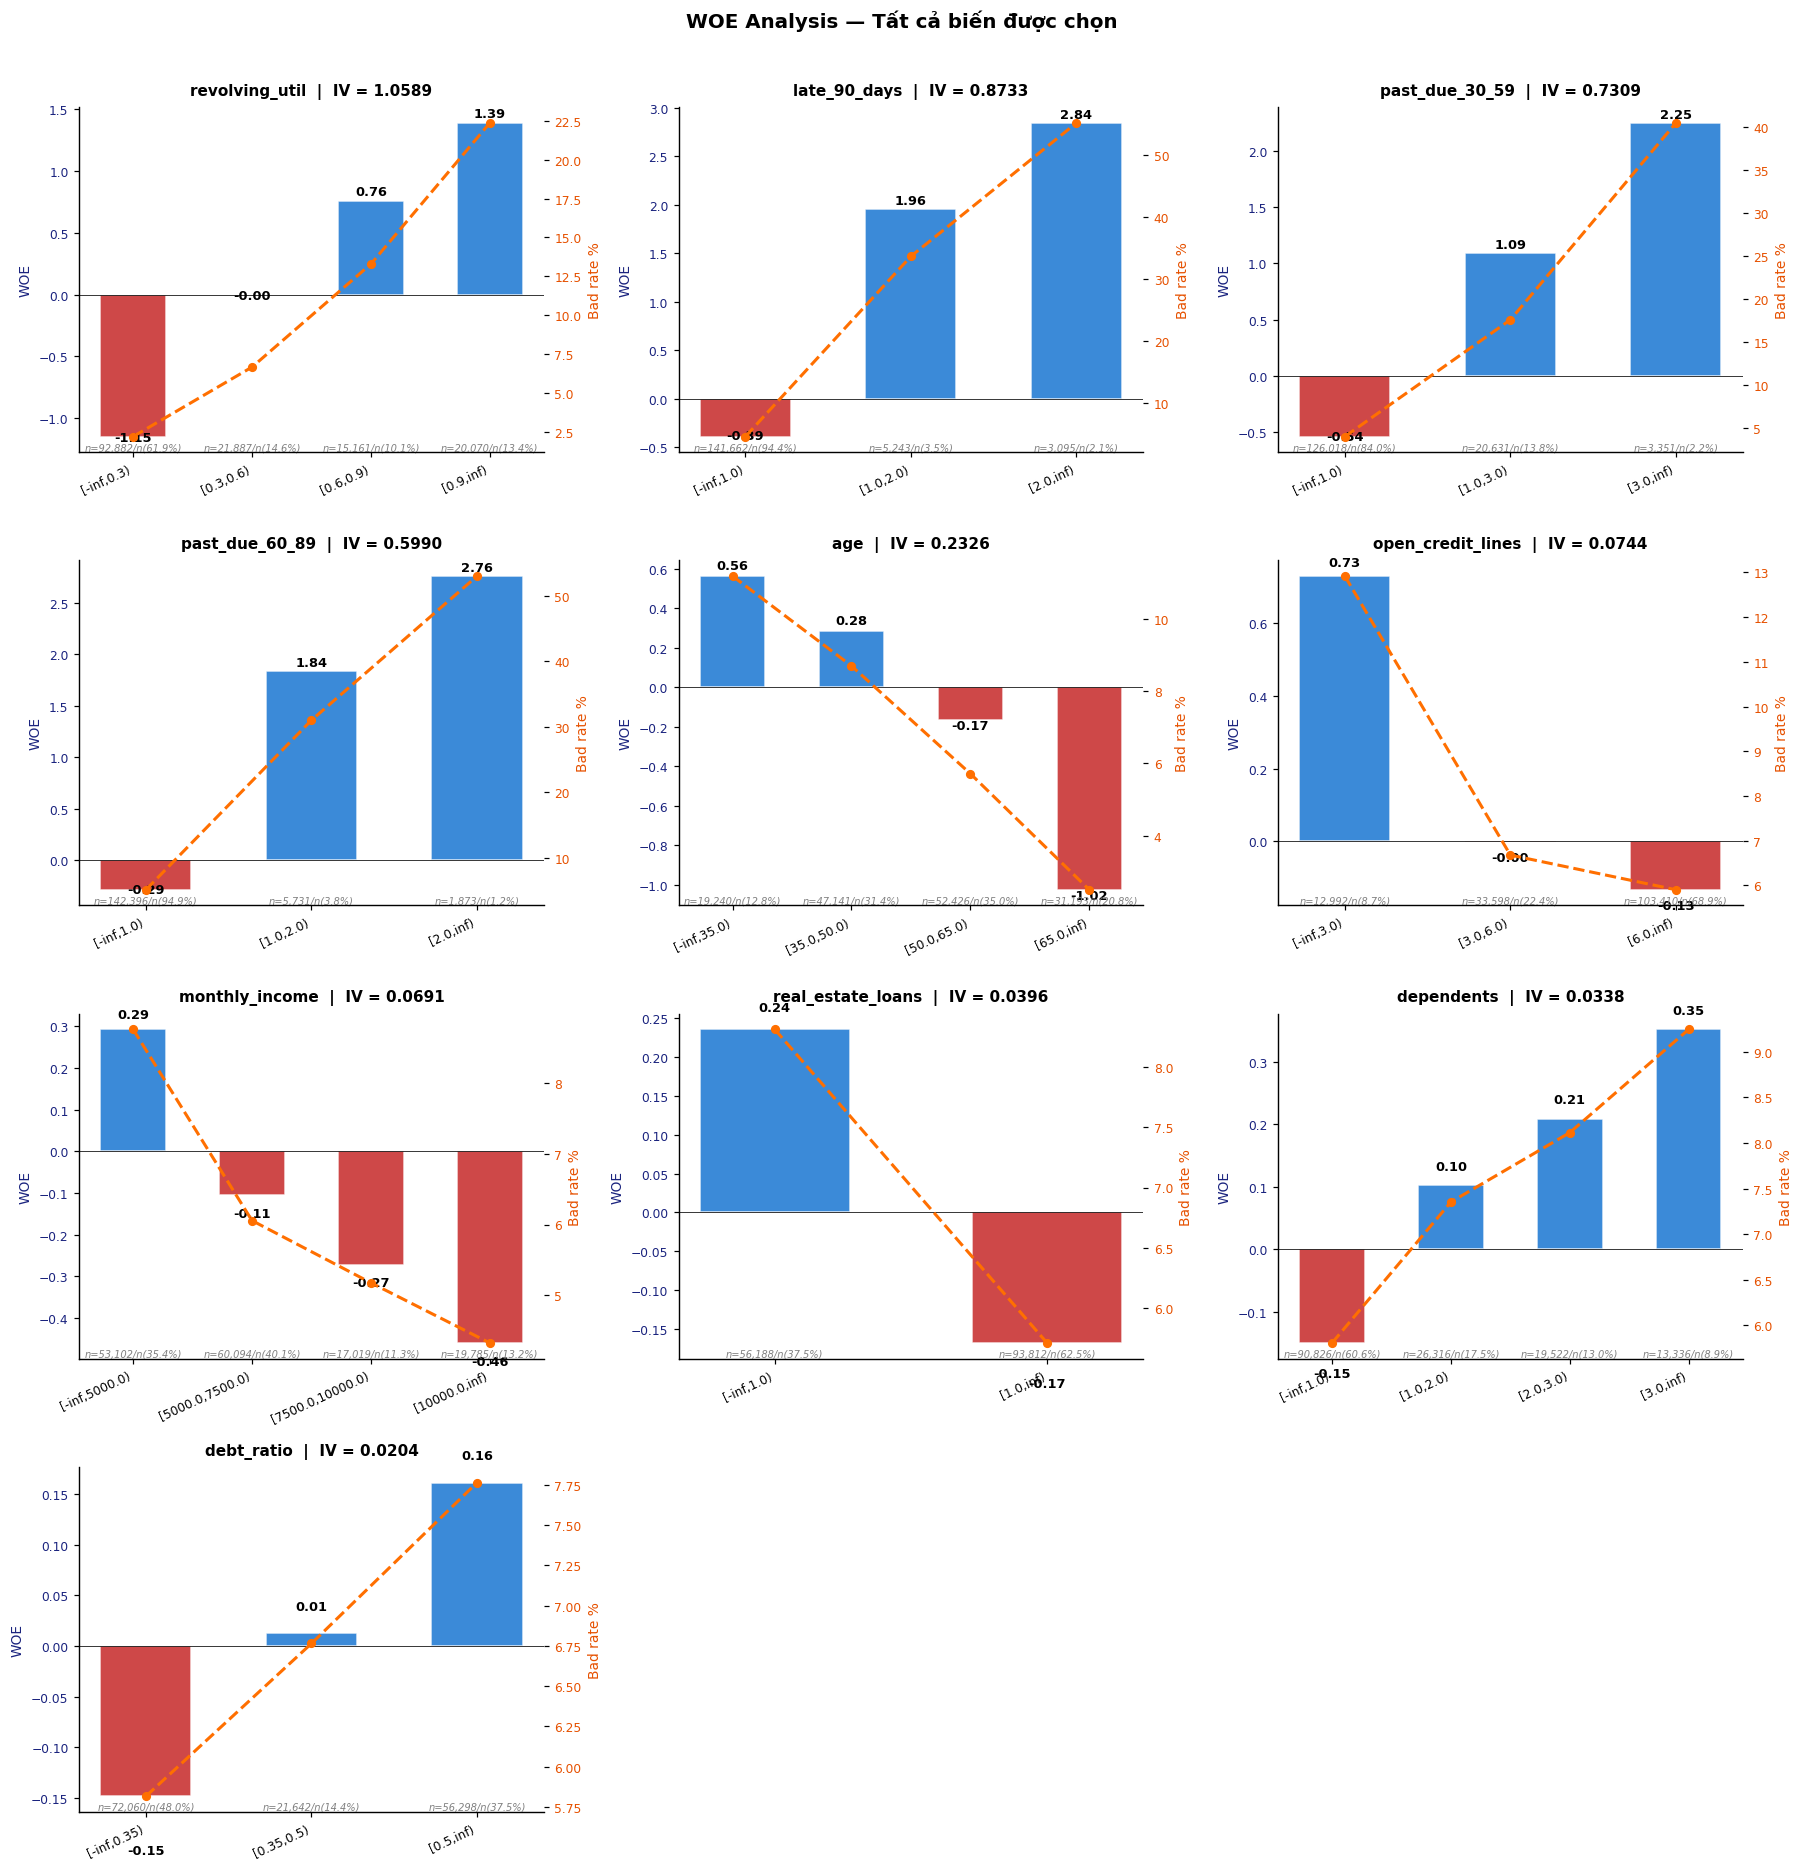

In [166]:
def plot_woe_bins(bins: dict, variables: list, ncols: int = 3):
    """
    Vẽ WOE chart cho danh sách biến.
    Mỗi subplot: cột WOE (màu theo dương/âm) + đường bad rate.
    """
    nrows = int(np.ceil(len(variables) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 5.5, nrows * 4.2))
    axes = np.array(axes).flatten()

    for i, var in enumerate(variables):
        ax1 = axes[i]
        tbl = bins[var].copy()

        # Labels ngắn gọn cho trục x
        labels = tbl["bin"].astype(str).str.replace("missing", "N/A")

        # ── Bar: WOE ────────────────────────────────────────────────────────
        bar_colors = [
            PALETTE["woe_pos"] if w >= 0 else PALETTE["woe_neg"]
            for w in tbl["woe"]
        ]
        bars = ax1.bar(
            range(len(tbl)), tbl["woe"],
            color=bar_colors, alpha=0.85, width=0.55, edgecolor="white",
        )

        # Thêm giá trị WOE lên bar
        for bar, woe_val in zip(bars, tbl["woe"]):
            ypos = bar.get_height() + 0.02 if woe_val >= 0 else bar.get_height() - 0.06
            ax1.text(bar.get_x() + bar.get_width() / 2, ypos,
                     f"{woe_val:.2f}", ha="center", va="bottom", fontsize=8.5,
                     fontweight="bold")

        ax1.axhline(0, color="black", linewidth=0.5, linestyle="-")
        ax1.set_xticks(range(len(tbl)))
        ax1.set_xticklabels(labels, rotation=25, ha="right", fontsize=8)
        ax1.set_ylabel("WOE", fontsize=9, color="#1A237E")
        ax1.tick_params(axis="y", labelcolor="#1A237E", labelsize=8)

        # ── Line: Bad rate (trục phụ) ────────────────────────────────────────
        ax2 = ax1.twinx()
        ax2.plot(range(len(tbl)), tbl["badprob"] * 100,
                 color="#FF6F00", marker="o", markersize=5,
                 linewidth=2, linestyle="--", label="Bad rate %")
        ax2.set_ylabel("Bad rate %", fontsize=9, color="#E65100")
        ax2.tick_params(axis="y", labelcolor="#E65100", labelsize=8)

        # ── IV annotation ────────────────────────────────────────────────────
        iv_val = tbl["bin_iv"].sum()
        ax1.set_title(
            f"{var}  |  IV = {iv_val:.4f}",
            fontsize=10, fontweight="bold", pad=8,
        )

        # Thêm count nhỏ phía dưới mỗi bar
        for j, (cnt, distr) in enumerate(zip(tbl["count"], tbl["count_distr"])):
            ax1.text(j, ax1.get_ylim()[0],
                     f"n={cnt:,}/n({distr*100:.1f}%)",
                     ha="center", va="bottom", fontsize=6.5,
                     color="gray", style="italic")

    # Tắt axes thừa
    for j in range(len(variables), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle("WOE Analysis — Tất cả biến được chọn",
                 fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("08_woe_bins_all.png", bbox_inches="tight")
    plt.show()


plot_woe_bins(bins_final, SELECTED_VARS, ncols=3)


#### WOE Analysis — Tất cả biến được chọn

#### Cách đọc biểu đồ
- **Cột xanh/đỏ** → WOE của từng bin (xanh = dương, đỏ = âm)
- **Đường cam** → Bad rate % theo từng bin
- **IV** → Tổng Information Value của biến

---

#### Nhóm rủi ro rất mạnh (IV > 0.5)

| Biến | IV | Nhận xét |
|---|---|---|
| `revolving_util` | 1.0589 | Tỷ lệ sử dụng hạn mức tín dụng càng cao, rủi ro càng lớn |
| `late_90_days` | 0.8733 | Số lần trễ hạn >90 ngày — phân tách rủi ro rất rõ |
| `past_due_30_59` | 0.7309 | Số lần trễ hạn 30–59 ngày |
| `past_due_60_89` | 0.5990 | Số lần trễ hạn 60–89 ngày |

WOE tăng đơn điệu từ trái sang phải → các biến này **phân tách tốt** và **ổn định** cho model.

---

#### Nhóm rủi ro trung bình (IV 0.05 – 0.3)

| Biến | IV | Nhận xét |
|---|---|---|
| `age` | 0.2327 | Người trẻ < 35 tuổi rủi ro hơn; người lớn tuổi ít rủi ro hơn |
| `open_credit_lines` | 0.0754 | Số dòng tín dụng mở ít thì rủi ro cao hơn |
| `monthly_income` | 0.0691 | Thu nhập càng cao càng ít rủi ro |
| `real_estate_loans` | 0.0554 | WOE hình chữ U — bin giữa `[1, 3)` rủi ro thấp nhất |

---

#### Nhóm rủi ro yếu (IV < 0.05)

| Biến | IV | Nhận xét |
|---|---|---|
| `dependents` | 0.0338 | Số người phụ thuộc — ảnh hưởng yếu |
| `debt_ratio` | 0.0223 | Tỷ lệ nợ — predictive power thấp, cân nhắc loại bỏ |

---

#### Tổng kết & Khuyến nghị

Ưu tiên **4 biến nhóm đầu** vào model do IV rất mạnh.  
`debt_ratio` và `dependents` có thể loại bỏ nếu cần đơn giản hóa model.

### 6. Kiểm tra Monotonicity

Một scorecard tốt cần WOE **đơn điệu** (monotone) — nghĩa là khi feature tăng thì WOE  
phải liên tục tăng hoặc liên tục giảm, không được zigzag.  
Nếu vi phạm monotonicity → cần điều chỉnh lại binning.

In [169]:
def check_monotonicity(bins: dict, variables: list) -> pd.DataFrame:
    """
    Kiểm tra WOE có đơn điệu không cho từng biến.
    Trả về DataFrame với cột: is_monotone, direction, n_violations.
    """
    results = []
    for var in variables:
        woe_vals = bins[var]["woe"].values
        if len(woe_vals) <= 2:
            results.append({
                "Variable": var, "is_monotone": True,
                "Direction": "N/A (<=2 bins)", "Violations": 0,
            })
            continue

        diffs = np.diff(woe_vals)
        n_pos = (diffs > 0).sum()
        n_neg = (diffs < 0).sum()

        if n_neg == 0:
            direction, is_mono = "Tăng dần ↑", True
        elif n_pos == 0:
            direction, is_mono = "Giảm dần ↓", True
        else:
            violations = min(n_pos, n_neg)
            direction  = f"Không đơn điệu ({'tăng chủ đạo' if n_pos > n_neg else 'giảm chủ đạo'})"
            is_mono    = False

        results.append({
            "Variable":    var,
            "is_monotone": is_mono,
            "Direction":   direction,
            "Violations":  0 if is_mono else min(n_pos, n_neg),
        })

    df_mono = pd.DataFrame(results)
    n_pass = df_mono["is_monotone"].sum()
    print(f"Monotonicity check: {n_pass}/{len(df_mono)} biến đạt")
    print()
    print(df_mono.to_string(index=False))
    return df_mono

mono_check = check_monotonicity(bins_final, SELECTED_VARS)

# Cảnh báo nếu có biến vi phạm
violations = mono_check[~mono_check["is_monotone"]]
if len(violations) > 0:
    print(f"\n⚠️  {len(violations)} biến vi phạm monotonicity:")
    for _, row in violations.iterrows():
        print(f"   → {row['Variable']}: {row['Violations']} điểm zigzag — cân nhắc điều chỉnh breaks_adj")
else:
    print("\n✓ Tất cả biến đều đơn điệu — binning tốt!")


Monotonicity check: 10/10 biến đạt

         Variable  is_monotone      Direction  Violations
   revolving_util         True     Tăng dần ↑           0
     late_90_days         True     Tăng dần ↑           0
   past_due_30_59         True     Tăng dần ↑           0
   past_due_60_89         True     Tăng dần ↑           0
              age         True     Giảm dần ↓           0
open_credit_lines         True     Giảm dần ↓           0
   monthly_income         True     Giảm dần ↓           0
real_estate_loans         True N/A (<=2 bins)           0
       dependents         True     Tăng dần ↑           0
       debt_ratio         True     Tăng dần ↑           0

✓ Tất cả biến đều đơn điệu — binning tốt!


#### 7. Transform dữ liệu sang WOE values

Sau khi đã hài lòng với bins, ta chuyển toàn bộ dataset:  
mỗi giá trị gốc được thay thế bằng WOE của bin tương ứng.

In [185]:
# ── Transform toàn bộ dataset ────────────────────────────────────────────────
df_woe = sc.woebin_ply(df, bins_final)

# Kiểm tra kết quả
print("Shape sau transform:", df_woe.shape)
print()
print("5 dòng đầu (cột WOE):")
woe_cols = [c for c in df_woe.columns if c.endswith("_woe")]
print(df_woe[woe_cols + ["target"]].head().to_string(index=False))


[INFO] converting into woe values ...
Shape sau transform: (150000, 12)

5 dòng đầu (cột WOE):
 past_due_60_89_woe  open_credit_lines_woe  debt_ratio_woe  revolving_util_woe  late_90_days_woe  real_estate_loans_woe  past_due_30_59_woe  dependents_woe  age_woe  monthly_income_woe  target
            -0.2882                -0.1326          0.1614              0.7613           -0.3897                -0.1684              1.0916          0.2093   0.2846             -0.2716       1
            -0.2882                -0.0008         -0.1484              1.3913           -0.3897                 0.2360             -0.5417          0.1026   0.2846              0.2926       0
            -0.2882                 0.7278         -0.1484              0.7613            1.9580                 0.2360              1.0916         -0.1501   0.2846              0.2926       0
            -0.2882                -0.0008         -0.1484             -1.1494           -0.3897                 0.2360             -

In [187]:
# ── Kiểm tra distribution của WOE values ─────────────────────────────────────
print("Thống kê mô tả WOE columns:")
woe_selected = [f"{v}_woe" for v in SELECTED_VARS if f"{v}_woe" in df_woe.columns]
print(df_woe[woe_selected].describe().round(4).to_string())
print()

# Kiểm tra không có NaN
nan_counts = df_woe[woe_selected].isnull().sum()
if nan_counts.sum() == 0:
    print("✓ Không có NaN trong WOE columns")
else:
    print("⚠️  Có NaN trong WOE columns:")
    print(nan_counts[nan_counts > 0])

Thống kê mô tả WOE columns:
       revolving_util_woe  late_90_days_woe  past_due_30_59_woe  past_due_60_89_woe     age_woe  open_credit_lines_woe  monthly_income_woe  real_estate_loans_woe  dependents_woe  debt_ratio_woe
count         150000.0000       150000.0000         150000.0000         150000.0000 150000.0000            150000.0000         150000.0000            150000.0000     150000.0000     150000.0000
mean              -0.4487           -0.2410             -0.2547             -0.1690     -0.1097                -0.0286             -0.0302                -0.0169         -0.0143         -0.0088
std                0.9666            0.6214              0.6774              0.5235      0.5311                 0.2392              0.2648                 0.1957          0.1789          0.1425
min               -1.1494           -0.3897             -0.5417             -0.2882     -1.0244                -0.1326             -0.4599                -0.1684         -0.1501         -0.1484
25

#### 8. Correlation giữa các WOE variables

Sau khi transform sang WOE, kiểm tra lại correlation để phát hiện **multicollinearity**.  
Nếu 2 biến có |correlation| > 0.75 → nên loại 1 (giữ biến có IV cao hơn).

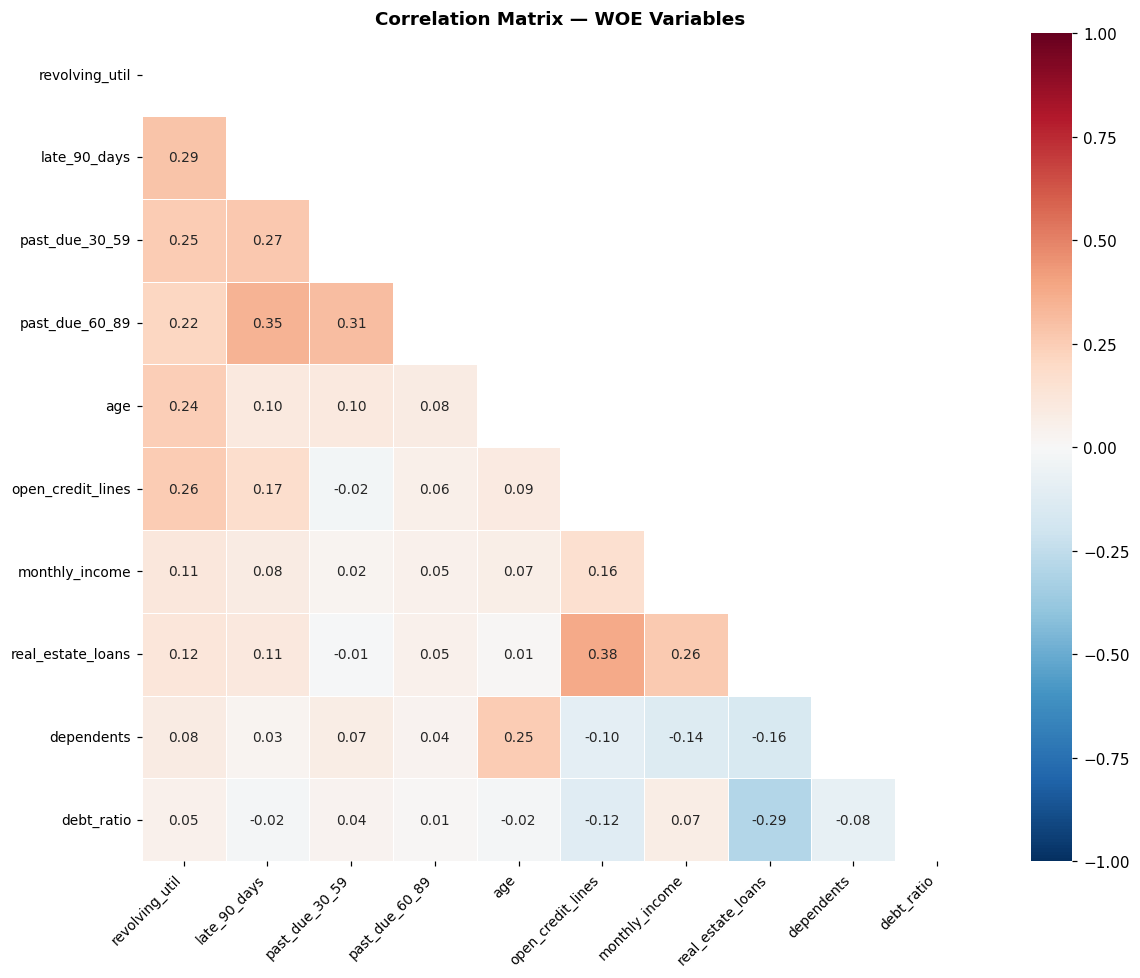

Cặp có |correlation| > 0.75 (nguy cơ multicollinearity):
  ✓ Không phát hiện multicollinearity nghiêm trọng


In [190]:
corr_woe = df_woe[woe_selected].corr()

# ── Heatmap ──────────────────────────────────────────────────────────────────
mask = np.triu(np.ones_like(corr_woe, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_woe,
    mask=mask,
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor="white",
    annot_kws={"size": 9},
    ax=ax,
)
ax.set_title("Correlation Matrix — WOE Variables", fontsize=12, fontweight="bold")
# Rút gọn tên cột cho dễ đọc
short_labels = [c.replace("_woe", "") for c in woe_selected]
ax.set_xticklabels(short_labels, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(short_labels, fontsize=9)
plt.tight_layout()
plt.savefig("09_woe_correlation.png", bbox_inches="tight")
plt.show()

# ── Cảnh báo multicollinearity ───────────────────────────────────────────────
print("Cặp có |correlation| > 0.75 (nguy cơ multicollinearity):")
found = False
for i in range(len(corr_woe.columns)):
    for j in range(i + 1, len(corr_woe.columns)):
        val = corr_woe.iloc[i, j]
        if abs(val) > 0.75:
            c1 = corr_woe.columns[i].replace("_woe","")
            c2 = corr_woe.columns[j].replace("_woe","")
            # Tìm IV của từng biến để gợi ý loại biến nào
            iv1 = iv_summary.loc[iv_summary["Variable"]==c1, "IV"].values[0]
            iv2 = iv_summary.loc[iv_summary["Variable"]==c2, "IV"].values[0]
            keep = c1 if iv1 >= iv2 else c2
            drop = c2 if iv1 >= iv2 else c1
            print(f"  {c1} ↔ {c2}  r={val:.3f}  → Giữ {keep} (IV cao hơn), cân nhắc loại {drop}")
            found = True
if not found:
    print("  ✓ Không phát hiện multicollinearity nghiêm trọng")

#### 9. Lưu bins & dữ liệu đã transform

In [193]:
import pickle

# ── Chuẩn bị final dataset cho Bước 3 ────────────────────────────────────────
# Chỉ giữ WOE columns của SELECTED_VARS + target
final_woe_cols = [f"{v}_woe" for v in SELECTED_VARS if f"{v}_woe" in df_woe.columns]
df_model_ready = df_woe[final_woe_cols + ["target"]].copy()

# Thêm flag missing (từ Bước 1) nếu có
if "monthly_income_missing" in df.columns:
    df_model_ready["monthly_income_missing"] = df["monthly_income_missing"].values

print(f"Dataset sẵn sàng cho model: {df_model_ready.shape}")
print(f"Columns: {list(df_model_ready.columns)}")

# ── Lưu files ────────────────────────────────────────────────────────────────
df_model_ready.to_csv("cs_woe_transformed.csv", index=False)
print("\n✓ Saved: cs_woe_transformed.csv")

with open("woe_bins.pkl", "wb") as f:
    pickle.dump(bins_final, f)
print("✓ Saved: woe_bins.pkl")

with open("selected_vars.pkl", "wb") as f:
    pickle.dump(SELECTED_VARS, f)
print("✓ Saved: selected_vars.pkl")

# ── Tóm tắt bước 2 ───────────────────────────────────────────────────────────
print()
print("=" * 55)
print("  TÓM TẮT BƯỚC 2 — WOE / IV ENCODING")
print("=" * 55)
print(f"  Tổng biến ban đầu  : {len(FEATURE_COLS)}")
print(f"  Biến giữ lại (IV≥0.02): {len(SELECTED_VARS)}")
print(f"  Biến loại bỏ      : {len(DROPPED_VARS)}")
print()
print("  Top 5 biến mạnh nhất (theo IV):")
for _, row in iv_summary.head(5).iterrows():
    print(f"    {row['Variable']:35s}  IV = {row['IV']:.4f}  {row['Classification']}")
print()
print("─── Bước tiếp theo: Bước 3 — Logistic Regression Scorecard ───")


Dataset sẵn sàng cho model: (150000, 12)
Columns: ['revolving_util_woe', 'late_90_days_woe', 'past_due_30_59_woe', 'past_due_60_89_woe', 'age_woe', 'open_credit_lines_woe', 'monthly_income_woe', 'real_estate_loans_woe', 'dependents_woe', 'debt_ratio_woe', 'target', 'monthly_income_missing']

✓ Saved: cs_woe_transformed.csv
✓ Saved: woe_bins.pkl
✓ Saved: selected_vars.pkl

  TÓM TẮT BƯỚC 2 — WOE / IV ENCODING
  Tổng biến ban đầu  : 10
  Biến giữ lại (IV≥0.02): 10
  Biến loại bỏ      : 0

  Top 5 biến mạnh nhất (theo IV):
    revolving_util                       IV = 1.0589  Suspicious
    late_90_days                         IV = 0.8733  Suspicious
    past_due_30_59                       IV = 0.7309  Suspicious
    past_due_60_89                       IV = 0.5990  Suspicious
    age                                  IV = 0.2326  Medium

─── Bước tiếp theo: Bước 3 — Logistic Regression Scorecard ───
